# 3 · Bayesian networks: macro drivers of crude oil
Monthly FRED data since 2000 (fed funds rate, CPI inflation, industrial production growth, broad dollar index) plus SPY are discretised into states. They feed a **discrete Bayesian network** that predicts the direction of *next month's* WTI crude-oil price change.

Two structures are compared:
1. an **expert** DAG encoding economic intuition;
2. a **data-learned** DAG from hill-climbing search with the BIC score.

Both are fitted on 2000-2015 and evaluated out-of-sample on 2016 onwards.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
spy = pd.read_csv("../data/spy_daily.csv", index_col=0, parse_dates=True)["SPY"]   # refresh: python scripts/fetch_data.py
from riskmodels import bayesnet
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import HillClimbSearch, BayesianEstimator
from pgmpy.inference import VariableElimination
import networkx as nx
import logging; logging.getLogger("pgmpy").setLevel(logging.ERROR)

In [2]:
macro = pd.read_csv("../data/macro_monthly.csv", index_col=0, parse_dates=True)
S = bayesnet.macro_states(macro, fit_end="2015-12-31")     # state cut-offs estimated on training data only
train, test = S.loc[:"2015-12-31"], S.loc["2016-01-01":]
print(f"{len(S)} months: train {len(train)}, test {len(test)}; P(oil up next month) train {train.oil_next.eq('up').mean():.1%}, test {test.oil_next.eq('up').mean():.1%}")
S.tail()

245 months: train 117, test 128; P(oil up next month) train 57.3%, test 58.6%


,rates,inflation,growth,dollar,equities,oil_next
observation_date,,,,,,
2026-05-31,high,high,mid,flat,strong,down
2026-06-30,high,high,low,flat,strong,down
2026-07-31,high,high,low,up,normal,up
2026-08-31,high,high,low,flat,normal,up
2026-09-30,high,high,mid,flat,normal,up


Learned edges: [('dollar', 'inflation'), ('inflation', 'growth'), ('inflation', 'rates'), ('rates', 'equities')]


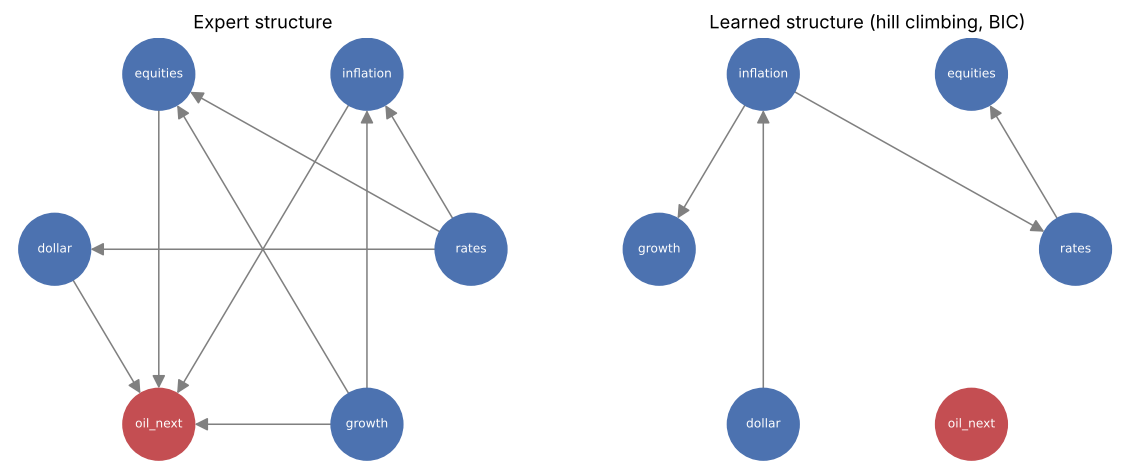

In [3]:
expert = DiscreteBayesianNetwork([("rates", "inflation"), ("growth", "inflation"), ("growth", "equities"), ("rates", "equities"),
                                   ("rates", "dollar"), ("dollar", "oil_next"), ("growth", "oil_next"), ("inflation", "oil_next"), ("equities", "oil_next")])
hc = HillClimbSearch(train)
learned_dag = hc.estimate(scoring_method="bic-d", max_indegree=3, show_progress=False)
learned = DiscreteBayesianNetwork(learned_dag.edges()); learned.add_nodes_from(S.columns)
for mdl in (expert, learned):
    mdl.add_cpds(*BayesianEstimator(mdl, train).get_parameters(prior_type="BDeu", equivalent_sample_size=10))
print("Learned edges:", sorted(learned.edges()))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (title, mdl) in zip(ax, [("Expert structure", expert), ("Learned structure (hill climbing, BIC)", learned)]):
    G = nx.DiGraph(mdl.edges()); G.add_nodes_from(S.columns)
    pos = nx.circular_layout(G)
    nx.draw_networkx(G, pos, ax=a, node_color=["#C44E52" if n == "oil_next" else "#4C72B0" for n in G.nodes], node_size=2200,
                     font_color="white", font_size=8, arrowsize=18, edge_color="grey")
    a.set_title(title); a.axis("off")
plt.savefig(IMG / "bayesnet_structures.png", bbox_inches="tight"); plt.show()

## Inference: what does the expert network say?

In [4]:
inf = VariableElimination(expert)
queries = [{}, {"dollar": "up"}, {"dollar": "down"}, {"growth": "high", "equities": "strong"}, {"growth": "low", "equities": "weak"}, {"inflation": "high"}]
rows = []
for ev in queries:
    q = inf.query(["oil_next"], evidence=ev or None, show_progress=False)
    rows.append({"evidence": ", ".join(f"{k}={v}" for k, v in ev.items()) or "(none)", "P(oil up next month)": float(q.values[q.state_names["oil_next"].index("up")])})
pd.DataFrame(rows).style.format({"P(oil up next month)": "{:.1%}"}).hide(axis="index")

evidence,P(oil up next month)
(none),53.9%
dollar=up,48.5%
dollar=down,56.0%
"growth=high, equities=strong",66.0%
"growth=low, equities=weak",45.8%
inflation=high,61.9%


## Out-of-sample evaluation

In [5]:
from sklearn.metrics import accuracy_score, roc_auc_score, brier_score_loss
y = (test.oil_next == "up").astype(int)
res = {}
for name, mdl in [("Expert BN", expert), ("Learned BN", learned)]:
    ve = VariableElimination(mdl)
    parents = [c for c in S.columns if c != "oil_next"]
    def p_up(evidence):
        q = ve.query(["oil_next"], evidence=evidence, show_progress=False)
        return float(q.values[q.state_names["oil_next"].index("up")])
    p = np.array([p_up(row[parents].to_dict()) for _, row in test.iterrows()])
    res[name] = {"accuracy": accuracy_score(y, p > 0.5), "AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p)}
base = train.oil_next.eq("up").mean()
res["Base rate (train)"] = {"accuracy": accuracy_score(y, np.full(len(y), base) > 0.5), "AUC": 0.5, "Brier": brier_score_loss(y, np.full(len(y), base))}
pd.DataFrame(res).T.round(3)

,accuracy,AUC,Brier
Expert BN,0.500,0.59,0.277
Learned BN,0.586,0.50,0.243
Base rate (train),0.586,0.50,0.243


**Takeaways**
* **The data and the experts disagree.** Hill climbing recovers sensible *macro* links (dollar → inflation → rates → equities, inflation → growth), but it attaches **no edge to next-month oil**. On its own evidence, monthly macro states carry too little information about oil's next move to justify the extra parameters, so the learned network falls back to the base rate.
* **The expert network tells a coherent economic story:** strong growth and equities lift P(oil up) to about 66% vs about 46% when both are weak, a strong dollar lowers it (≈ 48% vs 56%, the familiar inverse dollar-oil link), and high inflation raises it (≈ 62%).
* **Out-of-sample, that story ranks months somewhat** (AUC ≈ 0.59), **but it is over-confident.** Its probabilities are too extreme, so its Brier score is worse than simply predicting the base rate. With four parents and roughly ten years of monthly data, many conditional-probability cells rest on few observations.
* That is the real value of Bayesian networks in risk work: **transparent, queryable scenario probabilities** ("what if the dollar strengthens while growth stalls?"), combined with an honest test of how far to trust them.